# Стоит ли ПРАЙМ стимулировать совместное использование подписки?

Связано ли добавление участников в подписку с более высоким удержанием владельца и большей ценностью подписки, и есть ли смысл продуктово стимулировать шеринг?

Подписки с участниками более длительные - их реже отменяют, они дольше живут и приносят больше выручки. Если эффект устойчив внутри тарифов и не объясняется только возрастом подписки, ПРАЙМ стоит стимулировать владельцев подключать участников.

Основное зерно анализа оттока (подписка и 30-дневный период жизни). Такое зерно позволяет понять на каком месяце жизни подписки происходит отток 

# Подключение данных

In [1]:
import json
import sys

import numpy as np
import pandas as pd
from sqlalchemy import text

# get_engine() живёт в вашем репозитории, в src/prime/config.py.
# Она читает строку подключения из .env — поэтому пароля здесь нет.
try:
    from prime.config import get_engine
except ModuleNotFoundError:
    raise ModuleNotFoundError(
        "Пакет prime не найден: ноутбук запущен не в окружении prime-monitor.\n"
        f"Сейчас Python отсюда: {sys.executable}\n"
        "JupyterLab: закройте его, перейдите в корень prime-monitor и выполните uv run jupyter lab.\n"
        "VS Code: Select Kernel справа сверху -> .venv из папки prime-monitor."
    ) from None

engine = get_engine()


def q(sql: str, **params) -> pd.DataFrame:
    """Выполнить запрос и вернуть DataFrame. Соединение закрывается сразу."""
    try:
        with engine.connect() as conn:
            # Моменты времени считаем в UTC: так они у всех одинаковые.
            conn.execute(text("set time zone 'UTC'"))
            return pd.read_sql(text(sql), conn, params=params)
    finally:
        engine.dispose()


print("подключились как:", q("select current_user as login").iloc[0, 0])

подключились как: mskachkov


# Проверка таблиц

In [2]:
subs = q("""
    select
        subscription_id
        , owner_client_id
        , tariff_id
        , started_at
        , ended_at
        , cancel_reason
    from prime.subscriptions
    order by subscription_id
""")

In [3]:
members = q("""
    select
        subscription_id
        , client_id
        , joined_at
        , left_at
    from prime.subscription_members
    order by subscription_id, joined_at
""")

In [4]:
subs.head()

,subscription_id,owner_client_id,tariff_id,started_at,ended_at,cancel_reason
0,00003fba-1c0b-4a1e-8b22-43de749d09e2,7c4748a7-350d-4feb-9c2b-597a3c72c6a8,1,2026-06-17 08:52:02+00:00,NaT,NaN
1,000085d7-4189-4bfc-bfae-f161d5207e1f,60f191d6-1537-4960-9b5e-66deeed89234,2,2025-04-18 21:58:34+00:00,NaT,NaN
2,00009e4d-35fe-462d-b6bd-7cace10df3c1,fc8237ca-de35-4df5-8e8b-566eb767c5d4,1,2026-07-07 09:16:09+00:00,NaT,NaN
3,0000d915-849d-4297-9870-d27e6a63b66e,1cd4da19-458c-4acd-93a8-17798c1e70d1,2,2026-08-11 05:36:16+00:00,NaT,NaN
4,0000efe4-b659-4117-87d5-a50fd022135e,ca505aaa-d30a-4734-ac06-98871166707c,1,2026-08-12 16:30:59+00:00,NaT,NaN


In [5]:
members.head()

,subscription_id,client_id,joined_at,left_at
0,000085d7-4189-4bfc-bfae-f161d5207e1f,b70f273c-80f1-4b7f-94c8-d4469e1c719f,2025-04-24 21:58:34+00:00,NaT
1,000085d7-4189-4bfc-bfae-f161d5207e1f,b3f3f08e-1e5a-44f7-875f-81280c48571d,2025-04-24 21:58:34+00:00,2025-09-16 21:58:34+00:00
2,000085d7-4189-4bfc-bfae-f161d5207e1f,e6552c1a-3f05-4c92-b028-195bf67bced3,2025-05-07 21:58:34+00:00,NaT
3,000085d7-4189-4bfc-bfae-f161d5207e1f,fa4e9794-58bc-49cc-adbc-f430c694f6b8,2025-05-18 21:58:34+00:00,NaT
4,000085d7-4189-4bfc-bfae-f161d5207e1f,b860f845-66d2-4b09-8ef6-1bfb1a482d5a,2025-06-10 21:58:34+00:00,2025-08-21 21:58:34+00:00


In [6]:
print("subs:", len(subs))
print("members:", len(members))

subs: 333905
members: 555858


In [7]:
members.groupby("subscription_id").size().describe()

count    233733.000000
mean          2.378175
std           1.185105
min           1.000000
25%           1.000000
50%           2.000000
75%           3.000000
max           5.000000
dtype: float64

In [8]:
# один и тот же человек не записан дважды в одну подписку?
members.duplicated(
    subset=["subscription_id", "client_id"]
).sum()

np.int64(0)

In [9]:
# участник не мог присоединиться раньше старта подписки
check = members.merge(
    subs[["subscription_id", "started_at"]],
    on="subscription_id",
    how="left",
    validate="m:1"
)

(check["joined_at"] < check["started_at"]).sum()

np.int64(0)

In [10]:
# распределение: сколько подписок имеют 0 - 5 участников
n_members = (
    members.groupby("subscription_id")
    .size()
    .rename("n_members")
)

subs["subscription_id"].map(n_members).fillna(0).value_counts().sort_index()

subscription_id
0.0    100172
1.0     65982
2.0     66355
3.0     66111
4.0     17592
5.0     17693
Name: count, dtype: int64

In [11]:
# на всякий случай проверка на то что выход не может быть раньше входа
(
    members["left_at"].notna()
    & (members["left_at"] < members["joined_at"])
).sum()

np.int64(0)

In [12]:
print("joined:", members["joined_at"].min(), "—", members["joined_at"].max())
print("left:", members["left_at"].min(), "—", members["left_at"].max())

print("ended subs:", subs["ended_at"].min(), "—", subs["ended_at"].max())

joined: 2024-01-08 00:08:51+00:00 — 2026-10-27 20:30:50+00:00
left: 2024-02-24 04:53:23+00:00 — 2027-08-09 22:18:44+00:00
ended subs: 2024-02-06 00:08:24+00:00 — 2026-08-28 23:52:26+00:00


## Проверка на то, что нет клиентов, кто подключился к подписке после ее окончания

In [13]:
member_check = members.merge(
    subs[["subscription_id", "ended_at"]],
    on="subscription_id",
    how="left",
    validate="m:1"
)

(
    member_check["ended_at"].notna()
    & (member_check["joined_at"] > member_check["ended_at"])
).sum()

np.int64(13421)

In [14]:
bad = q("""
    select
        sm.subscription_id
        , sm.client_id
        , sm.joined_at
        , sm.left_at
        , s.started_at
        , s.ended_at
        , extract(epoch from (sm.joined_at - s.ended_at)) / 86400 as days_after_end
    from prime.subscription_members sm
    join prime.subscriptions s
        on sm.subscription_id = s.subscription_id
    where 1=1
    and s.ended_at is not null
    and sm.joined_at > s.ended_at
""")

print("Аномальных membership", len(bad))
print("Затронуто подписок", bad["subscription_id"].nunique())

bad["days_after_end"].describe()

Аномальных membership 13421
Затронуто подписок 8346


count    13421.000000
mean        16.149152
std          9.932584
min          0.000810
25%          8.000000
50%         16.000000
75%         23.000000
max         58.895162
Name: days_after_end, dtype: float64

In [15]:
join_offsets = q("""
    select
        round(extract(epoch from (sm.joined_at - s.started_at)) / 86400)::int as join_after_start_days
        , count(*) as memberships
    from prime.subscription_members sm
    join prime.subscriptions s
        on sm.subscription_id = s.subscription_id
    where 1=1
    group by round(extract(epoch from (sm.joined_at - s.started_at)) / 86400)::int
    order by join_after_start_days
""")

join_offsets

,join_after_start_days,memberships
0,0,9352
1,1,9219
2,2,9252
3,3,9317
4,4,9237
5,5,9291
6,6,9077
7,7,9268
8,8,9301
9,9,9119


In [16]:
print("Минимальный offset - ", join_offsets["join_after_start_days"].min())
print("Максимальный offset - ", join_offsets["join_after_start_days"].max())
print("Частота по дням")
print("min - ", join_offsets["memberships"].min())
print("max - ", join_offsets["memberships"].max())
print("mean - ", round(join_offsets["memberships"].mean(), 1))

Минимальный offset -  0
Максимальный offset -  59
Частота по дням
min -  9024
max -  9460
mean -  9264.3


In [17]:
bad_by_lifetime = q("""
    with member_lifetime as 
    (
        select
            sm.subscription_id
            , sm.client_id
            , floor(
                extract(epoch from (s.ended_at - s.started_at)) / 86400
            )::int as lifetime_days
            , case
                when sm.joined_at > s.ended_at then 1
                else 0
              end as is_bad
        from prime.subscription_members sm
        join prime.subscriptions s
            on sm.subscription_id = s.subscription_id
        where 1=1
        and s.ended_at is not null
    )
    select
        lifetime_days
        , count(*) as memberships
        , sum(is_bad) as bad
        , avg(is_bad::numeric) as bad_share
        , greatest(
            (59 - lifetime_days) / 60.0
            , 0
          ) as expected_bad_share
    from member_lifetime
    where 1=1
    group by lifetime_days
    order by lifetime_days
""")

bad_by_lifetime.head(60)

,lifetime_days,memberships,bad,bad_share,expected_bad_share
0,0,55,55,1.000000,0.983333
1,1,79,78,0.987342,0.966667
2,2,104,102,0.980769,0.950000
3,3,93,83,0.892473,0.933333
4,4,126,120,0.952381,0.916667
5,5,96,84,0.875000,0.900000
6,6,80,69,0.862500,0.883333
7,7,80,65,0.812500,0.866667
8,8,108,92,0.851852,0.850000
9,9,77,60,0.779221,0.833333


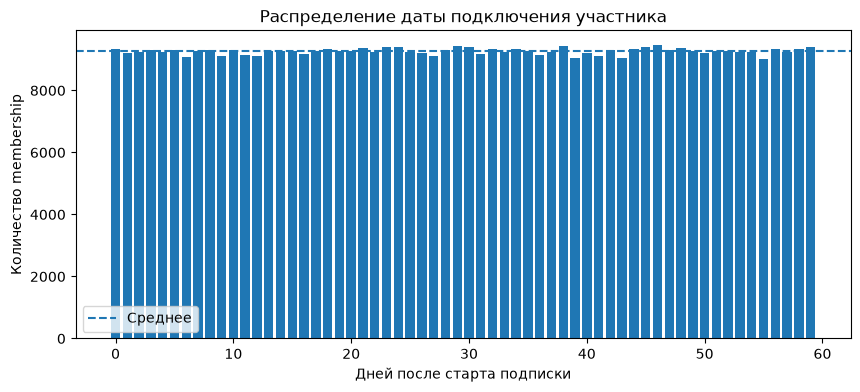

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.bar(
    join_offsets["join_after_start_days"],
    join_offsets["memberships"]
)

plt.axhline(
    join_offsets["memberships"].mean(),
    linestyle="--",
    label="Среднее"
)

plt.title("Распределение даты подключения участника")
plt.xlabel("Дней после старта подписки")
plt.ylabel("Количество membership")
plt.legend()

plt.show()

Проверка качества данных. В subscription_members обнаружено 13 421 участий в 8 346 подписках, где joined_at находится после subscriptions.ended_at. Дополнительно посмотрел, что дата подключения участника практически равномерно распределена в диапазоне 0–59 дней после начала подписки и формируется независимо от даты её окончания. Дальше следует исключить таких пользователей и рассматривать гипотезу без них. 

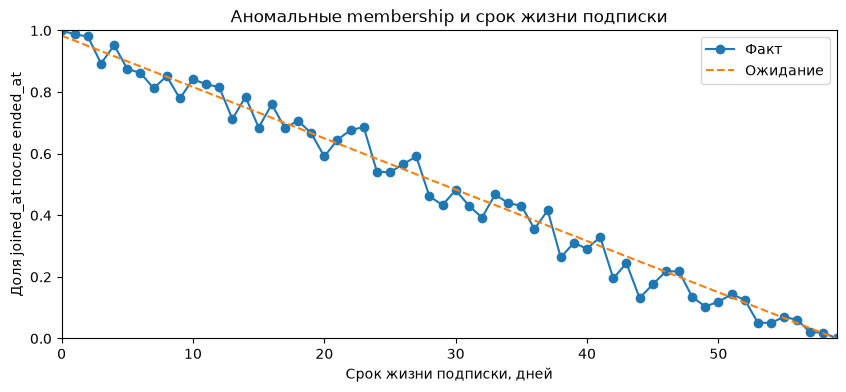

In [19]:
plt.figure(figsize=(10, 4))

plt.plot(
    bad_by_lifetime["lifetime_days"],
    bad_by_lifetime["bad_share"],
    marker="o",
    label="Факт"
)

plt.plot(
    bad_by_lifetime["lifetime_days"],
    bad_by_lifetime["expected_bad_share"],
    linestyle="--",
    label="Ожидание"
)

plt.xlim(0, 59)
plt.ylim(0, 1)

plt.title("Аномальные membership и срок жизни подписки")
plt.xlabel("Срок жизни подписки, дней")
plt.ylabel("Доля joined_at после ended_at")
plt.legend()

plt.show()

# Проверка гипотезы 1

## Сборка скорректированных данных

In [20]:
panel = q("""
    with months as 
    (
        select
            generate_series(
                '2025-01-01'::timestamptz
                , '2026-07-01'::timestamptz
                , interval '1 month'
            ) as month_start
    )
    , active_subs as 
    (
        select
            m.month_start
            , s.subscription_id
            , s.tariff_id
            , s.started_at
            , s.ended_at
        from months m
        inner join prime.subscriptions s
            on s.started_at <= m.month_start
            and 
            (
                s.ended_at is null
                or s.ended_at > m.month_start
            )
    )
    , member_counts as 
    (
        select
            a.month_start
            , a.subscription_id
            , count(sm.client_id) as n_members
        from active_subs a
        left join prime.subscription_members sm
            on sm.subscription_id = a.subscription_id
            and sm.joined_at <= a.month_start
            and 
            (
                sm.left_at is null
                or sm.left_at > a.month_start
            )
        where 1=1
        group by a.month_start, a.subscription_id
    )
    select
        a.month_start
        , a.subscription_id
        , a.tariff_id
        , mc.n_members
        , case
            when a.ended_at >= a.month_start
            and a.ended_at < a.month_start + interval '1 month'
            then 1
            else 0
          end as churned
          , extract(
                epoch from (a.month_start - a.started_at)
            ) / 86400 as age_days
    from active_subs a
    join member_counts mc
        on a.month_start = mc.month_start
        and a.subscription_id = mc.subscription_id
    where 1=1
    order by a.month_start, a.subscription_id
""")

In [21]:
panel["sharing_group"] = pd.cut(
    panel["n_members"]
    , bins=[-1, 0, 1, 2, float("inf")]
    , labels=["0", "1", "2", "3+"]
)

In [22]:
panel["age_group"] = pd.cut(
    panel["age_days"]
    , bins=[0, 90, 180, 365, float("inf")]
    , labels=["0–3 мес.", "3–6 мес.", "6–12 мес.", "12+ мес."]
)



In [23]:
age_result = (
    panel
    .groupby(
        ["age_group", "sharing_group"]
        , observed=True
    )
    .agg(
        observations=("subscription_id", "size")
        , churn=("churned", "mean")
    )
)

age_result["churn"] *= 100

age_result

observations     churn
age_group sharing_group                        
0–3 мес.  0                    272193  4.155140
          1                    132887  4.247970
          2                     92740  4.249515
          3+                    96180  4.242046
3–6 мес.  0                    160299  4.183432
          1                    106681  4.158191
          2                    107270  4.004848
          3+                   148893  4.120409
6–12 мес. 0                    276568  3.999017
          1                    187627  4.005287
          2                    183724  4.031047
          3+                   219915  3.971989
12+ мес.  0                    258396  3.719872
          1                    176571  3.679540
          2                    167947  3.717840
          3+                   188376  3.754725

In [24]:
sharing_result = (
    panel
    .groupby("sharing_group", observed=True)
    .agg(
        observations=("subscription_id", "size")
        , subscriptions=("subscription_id", "nunique")
        , churned=("churned", "sum")
        , churn=("churned", "mean")
    )
)

sharing_result["churn"] *= 100

sharing_result

,observations,subscriptions,churned,churn
sharing_group,,,,
0,967456,171318,38688,3.998942
1,603766,110092,24093,3.990453
2,551681,86413,21887,3.967329
3+,653364,78366,26023,3.982925


In [25]:
tariff_result = (
    panel
    .groupby(
        ["tariff_id", "sharing_group"]
        , observed=True
    )
    .agg(
        observations=("subscription_id", "size")
        , churn=("churned", "mean")
    )
)

tariff_result["churn"] *= 100

tariff_result

observations     churn
tariff_id sharing_group                        
1         0                    610963  4.023321
          1                    436015  3.982890
          2                    393093  3.983536
          3+                   283234  3.979042
2         0                    356493  3.957160
          1                    167751  4.010110
          2                    158588  3.927157
          3+                   370130  3.985897

## Вывод по гипотезе 1

Гипотеза не подтвердилась. Общий отток составляет около 4% независимо от числа участников. Результат сохраняется отдельно внутри тарифов и внутри групп по возрасту подписки. Следовательно, стимулировать шеринг именно как инструмент снижения оттока оснований нет.

# Гипотеза 2 - Владельцы подписок, кто пользуется сервисом в первые 30 дней, имею отток в следующие 60 дней меньше чем те, кто не попользовался

## Проверка данных

In [26]:
usage = q("""
    select *
    from prime.service_usage
    limit 5
""")

usage

,usage_id,client_id,service_id,started_at,ended_at,device_type
0,cdb8d62c-83c2-4505-9414-649d2875cc5c,6cd6cbd5-9c31-4ae9-9270-daf8623b5738,2,2025-12-27 07:25:07+00:00,2025-12-27 07:58:55+00:00,mobile
1,0b5d4197-e757-4270-8067-ec942ac6b4c4,3670c013-ed4e-4869-92ab-efc59fbfe442,9,2025-09-26 18:31:29+00:00,2025-09-26 19:02:45+00:00,mobile
2,dbeb828e-a605-496a-9414-267b6f3653b8,0084e4a7-dc5e-4c98-8d05-59e4f3b0d862,3,2026-02-11 15:07:36+00:00,2026-02-11 15:26:43+00:00,desktop
3,df540a2c-c10e-4419-b069-1a0f89b23e0d,fe6771c4-269f-4ab1-986f-b559f6da8400,1,2025-11-27 05:51:11+00:00,2025-11-27 05:54:23+00:00,mobile
4,7d237fbf-683f-42da-8a04-e7b9f5d3ca5d,16b34a68-06bf-4f37-8bf7-a5f04ea6d87b,1,2026-05-21 02:16:17+00:00,2026-05-21 02:48:15+00:00,mobile


In [27]:
usage_info = q("""
    select
        min(started_at) as min_usage_at
        , max(started_at) as max_usage_at
        , count(*) as usages
        , count(distinct client_id) as clients
        , count(distinct service_id) as services
    from prime.service_usage
    where 1=1
""")

usage_info

,min_usage_at,max_usage_at,usages,clients,services
0,2025-01-06 00:00:05+00:00,2026-08-29 23:59:55+00:00,7968633,399303,12


In [28]:
usage_services = q("""
    select
        service_id
        , count(*) as usages
        , count(distinct client_id) as clients
    from prime.service_usage
    where 1=1
    group by service_id
    order by usages desc
""")

usage_services

,service_id,usages,clients
0,8,1187602,287034
1,1,1187588,287601
2,5,1187068,287055
3,3,1186655,286789
4,9,1186194,287007
5,6,291378,120183
6,10,290990,120116
7,11,290554,120259
8,7,290408,119988
9,4,290218,120043


In [29]:
usage_devices = q("""
    select
        device_type
        , count(*) as usages
    from prime.service_usage
    where 1=1
    group by device_type
    order by usages desc
""")

usage_devices

,device_type,usages
0,mobile,4859484
1,desktop,1513926
2,tv,1037391
3,tablet,557832


In [30]:
usage_mart = q("""
with eligible_subs as 
(
    select
        s.subscription_id
        , s.owner_client_id
        , s.tariff_id
        , s.started_at
        , s.ended_at
    from prime.subscriptions s
    where 1=1
    and s.started_at >= '2025-01-06'::timestamptz
    and s.started_at + interval '90 day' <= '2026-08-29'::timestamptz
    and 
    (
        s.ended_at is null
        or s.ended_at >= s.started_at + interval '30 day'
    )
)
, usage_30 as 
(
    select
        s.subscription_id
        , count(u.usage_id) as n_usages_30
        , count(distinct u.service_id) as n_services_30
    from eligible_subs s
    left join prime.service_usage u
        on u.client_id = s.owner_client_id
        and u.started_at >= s.started_at
        and u.started_at < s.started_at + interval '30 day'
    where 1=1
    group by s.subscription_id
)
select
    s.subscription_id
    , s.tariff_id
    , s.started_at
    , u.n_usages_30
    , u.n_services_30
    , case
        when u.n_usages_30 > 0 then 1
        else 0
      end as used_30
    , case
        when s.ended_at >= s.started_at + interval '30 day'
        and s.ended_at < s.started_at + interval '90 day'
        then 1
        else 0
      end as churn_31_90
from eligible_subs s
join usage_30 u
    on s.subscription_id = u.subscription_id
where 1=1
order by s.subscription_id
""")

In [31]:
print("Строк:", len(usage_mart))
print(
    "Уникальных подписок:",
    usage_mart["subscription_id"].nunique()
)

usage_mart.head()

Строк: 184599
Уникальных подписок: 184599


,subscription_id,tariff_id,started_at,n_usages_30,n_services_30,used_30,churn_31_90
0,000085d7-4189-4bfc-bfae-f161d5207e1f,2,2025-04-18 21:58:34+00:00,2,2,1,0
1,00018019-4126-41c2-97cb-dbd0549dfa18,1,2025-09-01 08:55:18+00:00,0,0,0,0
2,000189ec-1ec0-496d-b990-e9a41723ae68,1,2025-01-25 02:32:10+00:00,0,0,0,0
3,00019f17-8001-4199-82d4-fc0d8e258839,1,2025-04-25 21:34:44+00:00,3,3,1,0
4,0002aff7-a530-4f44-867c-bbd76addfc1b,2,2026-04-20 18:49:06+00:00,5,4,1,0


In [32]:
usage_result = (
    usage_mart
    .groupby("used_30")
    .agg(
        subscriptions=("subscription_id", "size")
        , churn=("churn_31_90", "mean")
        , avg_usages=("n_usages_30", "mean")
        , avg_services=("n_services_30", "mean")
    )
)

usage_result["churn"] *= 100

usage_result

,subscriptions,churn,avg_usages,avg_services
used_30,,,,
0,73184,8.280498,0.000000,0.000000
1,111415,8.417179,2.546165,2.049661


## Вывод по гипотезе 2

Использование хотя бы одного сервиса в первые 30 дней не связано со снижением оттока. Гипотеза о том, что использование в первые 30 дней подписки повышает удержание, не подтвердилась.

In [33]:
usage_mart["usage_group"] = pd.cut(
    usage_mart["n_usages_30"]
    , bins=[-1, 0, 1, 3, 5, float("inf")]
    , labels=["0", "1", "2–3", "4–5", "6+"]
)

usage_intensity = (
    usage_mart
    .groupby("usage_group", observed=True)
    .agg(
        subscriptions=("subscription_id", "size")
        , churn=("churn_31_90", "mean")
    )
)

usage_intensity["churn"] *= 100

usage_intensity

,subscriptions,churn
usage_group,,
0,73184,8.280498
1,47121,8.410263
2–3,41219,8.452413
4–5,13670,8.588149
6+,9405,8.048910


In [34]:
usage_mart["services_group"] = pd.cut(
    usage_mart["n_services_30"]
    , bins=[-1, 0, 1, 2, float("inf")]
    , labels=["0", "1", "2", "3+"]
)

services_result = (
    usage_mart
    .groupby("services_group", observed=True)
    .agg(
        subscriptions=("subscription_id", "size")
        , churn=("churn_31_90", "mean")
    )
)

services_result["churn"] *= 100

services_result

,subscriptions,churn
services_group,,
0,73184,8.280498
1,51404,8.439032
2,29423,8.360806
3+,30588,8.434680


# Гипотеза 3 - Повышенный отток сосредоточен в первые месяцы жизни подписки и связан с конкретными причинами отмены

In [35]:
lifecycle = q("""
with params as 
(
    select
        '2026-08-30 00:00:00+00'::timestamptz as observation_end
)
, subscription_periods as 
(
    select
        s.subscription_id
        , s.tariff_id
        , s.started_at
        , s.ended_at
        , g.period_n
        , s.started_at + g.period_n * interval '30 day' as period_start
        , s.started_at + (g.period_n + 1) * interval '30 day' as period_end
    from prime.subscriptions s
    cross join lateral generate_series(0, 40) as g(period_n)
    cross join params p
    where 1=1
    and s.started_at + (g.period_n + 1) * interval '30 day' <= p.observation_end
    and (
        s.ended_at is null
        or s.ended_at > s.started_at + g.period_n * interval '30 day'
    )
)
select
    subscription_id
    , tariff_id
    , period_n + 1 as life_month
    , period_start
    , period_end
    , case
        when ended_at > period_start
        and ended_at <= period_end
        then 1
        else 0
      end as churned
from subscription_periods
where 1=1
order by subscription_id, life_month
""")

In [36]:
print("Строк:", len(lifecycle))

print(
    "Дублей subscription × life_month:",
    lifecycle.duplicated(
        ["subscription_id", "life_month"]
    ).sum()
)

lifecycle.head()

Строк: 3492263
Дублей subscription × life_month: 0


,subscription_id,tariff_id,life_month,period_start,period_end,churned
0,00003fba-1c0b-4a1e-8b22-43de749d09e2,1,1,2026-06-17 08:52:02+00:00,2026-07-17 08:52:02+00:00,0
1,00003fba-1c0b-4a1e-8b22-43de749d09e2,1,2,2026-07-17 08:52:02+00:00,2026-08-16 08:52:02+00:00,0
2,000085d7-4189-4bfc-bfae-f161d5207e1f,2,1,2025-04-18 21:58:34+00:00,2025-05-18 21:58:34+00:00,0
3,000085d7-4189-4bfc-bfae-f161d5207e1f,2,2,2025-05-18 21:58:34+00:00,2025-06-17 21:58:34+00:00,0
4,000085d7-4189-4bfc-bfae-f161d5207e1f,2,3,2025-06-17 21:58:34+00:00,2025-07-17 21:58:34+00:00,0


In [37]:
lifecycle_result = (
    lifecycle
    .groupby("life_month")
    .agg(
        observations=("subscription_id", "size")
        , churned=("churned", "sum")
        , churn=("churned", "mean")
    )
)

lifecycle_result["churn"] *= 100

lifecycle_result.head(20)

,observations,churned,churn
life_month,,,
1,323219,14045,4.345351
2,299056,12832,4.290835
3,276440,11701,4.232745
4,255684,10821,4.232177
5,236142,9950,4.213566
6,217602,9017,4.143804
7,200370,8382,4.183261
8,184018,7721,4.195785
9,168709,6907,4.094032


In [38]:
lifecycle["life_month_group"] = lifecycle["life_month"].clip(upper=18)

lifecycle_plot = (
    lifecycle
    .groupby("life_month_group")
    .agg(
        observations=("subscription_id", "size")
        , churn=("churned", "mean")
    )
    .reset_index()
)

lifecycle_plot["churn"] *= 100

lifecycle_plot["life_month_label"] = (
    lifecycle_plot["life_month_group"]
    .astype(str)
)

lifecycle_plot.loc[
    lifecycle_plot["life_month_group"] == 18,
    "life_month_label"
] = "18+"

lifecycle_plot

,life_month_group,observations,churn,life_month_label
0,1,323219,4.345351,1
1,2,299056,4.290835,2
2,3,276440,4.232745,3
3,4,255684,4.232177,4
4,5,236142,4.213566,5
5,6,217602,4.143804,6
6,7,200370,4.183261,7
7,8,184018,4.195785,8
8,9,168709,4.094032,9
9,10,154561,4.150465,10


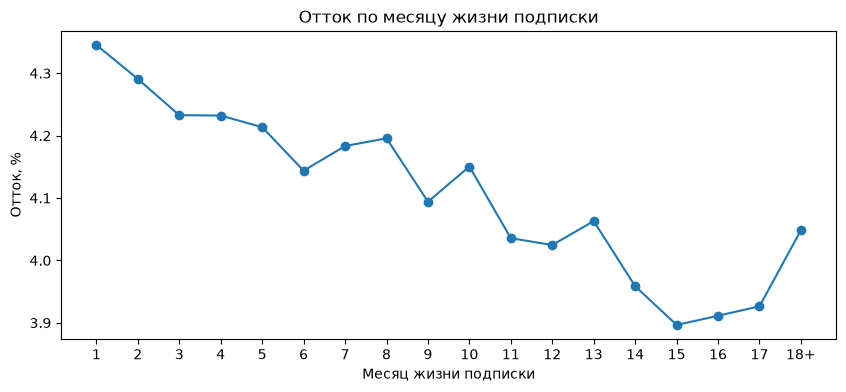

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.plot(
    lifecycle_plot["life_month_label"]
    , lifecycle_plot["churn"]
    , marker="o"
)

plt.title("Отток по месяцу жизни подписки")
plt.xlabel("Месяц жизни подписки")
plt.ylabel("Отток, %")

plt.show()

In [40]:
reason_lifecycle = q("""
with ended as 
(
    select
        subscription_id
        , cancel_reason
        , ceil(
            extract(epoch from (ended_at - started_at)) / 86400 / 30.0
          )::int as life_month
    from prime.subscriptions
    where 1=1
    and ended_at is not null
)
select
    case
        when life_month between 1 and 3 then '1–3'
        when life_month between 4 and 6 then '4–6'
        when life_month between 7 and 12 then '7–12'
        when life_month between 13 and 17 then '13–17'
    end as life_group
    , cancel_reason
    , count(*) as cancellations
from ended
where 1=1
and life_month between 1 and 17
group by life_group, cancel_reason
order by life_group, cancellations desc
""")

reason_lifecycle

,life_group,cancel_reason,cancellations
0,1–3,not_using,14179
1,1–3,too_expensive,10169
2,1–3,switched,7637
3,1–3,payment_failed,5827
4,1–3,other,4140
5,13–17,not_using,7610
6,13–17,too_expensive,5524
7,13–17,switched,4022
8,13–17,payment_failed,3202
9,13–17,other,2212


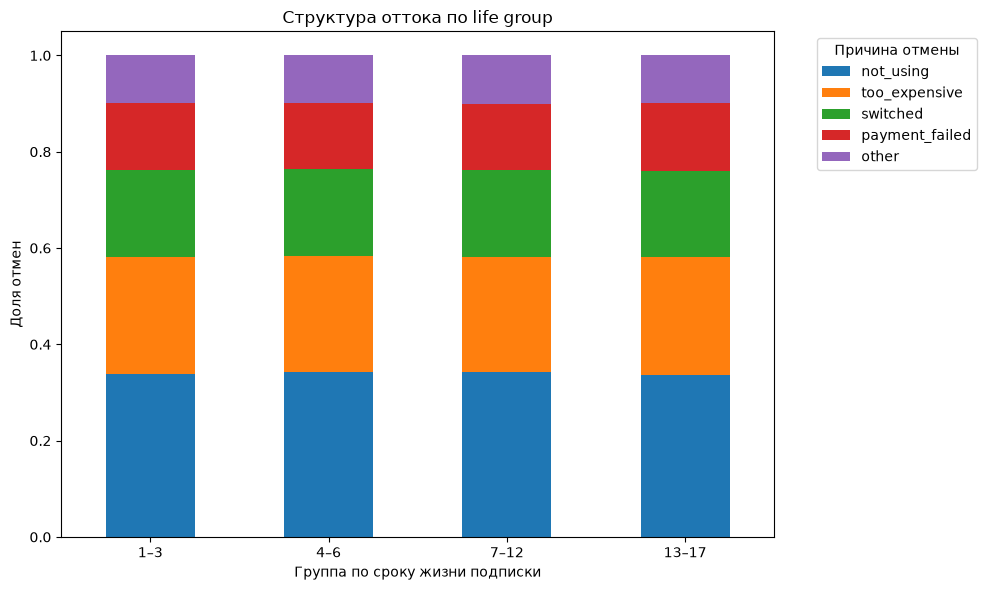

In [41]:
reason_share = reason_lifecycle.copy()

reason_share["share"] = (
    reason_share["cancellations"]
    / reason_share.groupby("life_group")["cancellations"].transform("sum")
)

life_order = ["1–3", "4–6", "7–12", "13–17"]
reason_order = [
    "not_using",
    "too_expensive",
    "switched",
    "payment_failed",
    "other"
]

reason_share["life_group"] = pd.Categorical(
    reason_share["life_group"],
    categories=life_order,
    ordered=True
)

reason_share["cancel_reason"] = pd.Categorical(
    reason_share["cancel_reason"],
    categories=reason_order,
    ordered=True
)

plot_df = (
    reason_share
    .pivot(index="life_group", columns="cancel_reason", values="share")
    .fillna(0)
    .sort_index()
)

ax = plot_df.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

ax.set_title("Структура оттока по life group")
ax.set_xlabel("Группа по сроку жизни подписки")
ax.set_ylabel("Доля отмен")
ax.legend(title="Причина отмены", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Вывод по гипотезе 3

Структура причин оттока практически не меняется по мере жизни подписки. Во всех группах основная причина это not_using (около 34%), далее идут too_expensive (~24%), switched (~18%) и payment_failed (~14%). Получается, что более высокий отток на ранних этапах жизни подписки не объясняется какой-то конкретной причиной отмены.

In [42]:
tariff_lifecycle = (
    lifecycle[
        lifecycle["life_month"] <= 17
    ]
    .groupby(
        ["life_month", "tariff_id"]
    )
    .agg(
        observations=("subscription_id", "size")
        , churn=("churned", "mean")
    )
    .reset_index()
)

tariff_lifecycle["churn"] *= 100

tariff_lifecycle.head(20)

,life_month,tariff_id,observations,churn
0,1,1,200900,4.346441
1,1,2,122319,4.343561
2,2,1,185820,4.345603
3,2,2,113236,4.200961
4,3,1,171645,4.207521
5,3,2,104795,4.274059
6,4,1,158895,4.248718
7,4,2,96789,4.205023
8,5,1,146748,4.213345
9,5,2,89394,4.213929


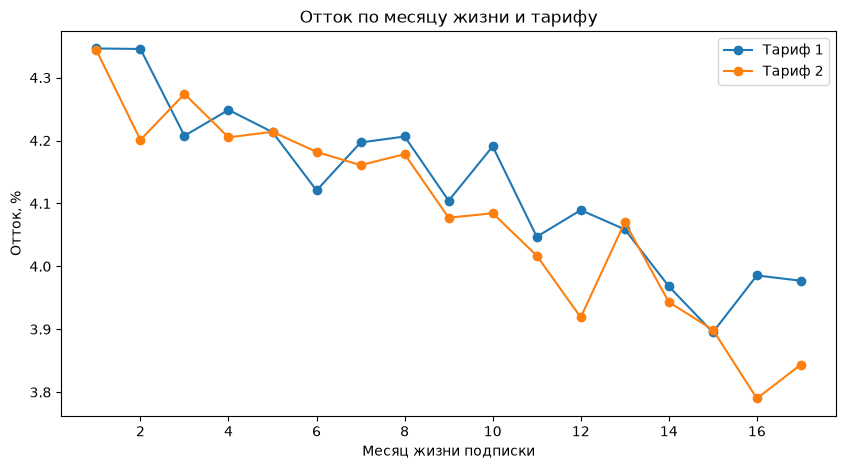

In [43]:
plt.figure(figsize=(10, 5))

for tariff_id, data in tariff_lifecycle.groupby("tariff_id"):
    plt.plot(
        data["life_month"]
        , data["churn"]
        , marker="o"
        , label=f"Тариф {tariff_id}"
    )

plt.title("Отток по месяцу жизни и тарифу")
plt.xlabel("Месяц жизни подписки")
plt.ylabel("Отток, %")
plt.legend()
plt.show()

# Гипотеза 4 - Каналы привлечения отличаются по качеству клиентов - часть каналов приводит подписчиков с существенно более высоким оттоком в первые месяцы жизни подписки

Какие каналы приводят наиболее устойчивых подписчиков ПРАЙМ, а какие создают повышенный ранний отток, и стоит ли перераспределять маркетинговые расходы?

## Подготовка данных

In [44]:
channel_lifecycle = q("""
with params as 
(
    select '2026-08-30 00:00:00+00'::timestamptz as observation_end
)
, subscription_periods as (
    select
        s.subscription_id
        , c.acquisition_channel
        , g.period_n + 1 as life_month
        , s.started_at + g.period_n * interval '30 day' as period_start
        , s.started_at + (g.period_n + 1) * interval '30 day' as period_end
        , s.ended_at
    from prime.subscriptions s
    join prime.clients c
        on s.owner_client_id = c.client_id
    cross join lateral generate_series(0, 16) as g(period_n)
    cross join params p
    where 1=1
    and s.started_at + (g.period_n + 1) * interval '30 day' <= p.observation_end
    and 
    (
        s.ended_at is null
        or s.ended_at > s.started_at + g.period_n * interval '30 day'
    )
)
select
    life_month
    , acquisition_channel
    , count(*) as observations
    , avg(
        case
            when ended_at > period_start
            and ended_at <= period_end
            then 1.0
            else 0.0
        end
      ) * 100 as churn
from subscription_periods
where 1=1
group by life_month, acquisition_channel
order by life_month, acquisition_channel
""")

channel_lifecycle.head(20)

,life_month,acquisition_channel,observations,churn
0,1,crm,37838,3.414557
1,1,organic,76278,2.165762
2,1,partner_telecom,56883,4.692087
3,1,performance,69836,5.454207
4,1,referral,25091,2.718106
5,1,social,50788,7.218241
6,1,NaN,6505,4.227517
7,2,crm,35266,3.320479
8,2,organic,72138,2.252627
9,2,partner_telecom,52742,4.757120


In [45]:
early_channel = (
    channel_lifecycle[
        channel_lifecycle["life_month"].between(1, 3)
    ]
    .groupby("acquisition_channel")
    .apply(
        lambda x: pd.Series({
            "observations": x["observations"].sum(),
            "churn": (
                (x["churn"] * x["observations"]).sum()
                / x["observations"].sum()
            )
        }),
        include_groups=False
    )
    .sort_values("churn", ascending=False)
)

early_channel

,observations,churn
acquisition_channel,,
social,137117.0,7.011530
performance,191694.0,5.439398
partner_telecom,158440.0,4.750694
crm,106060.0,3.399962
referral,70887.0,2.695840
organic,216422.0,2.201717


In [46]:
channel_tariff = q("""
with params as 
(
    select '2026-08-30 00:00:00+00'::timestamptz as observation_end
)
, subscription_periods as 
(
    select
        s.subscription_id
        , s.tariff_id
        , c.acquisition_channel
        , g.period_n + 1 as life_month
        , s.started_at + g.period_n * interval '30 day' as period_start
        , s.started_at + (g.period_n + 1) * interval '30 day' as period_end
        , s.ended_at
    from prime.subscriptions s
    join prime.clients c
        on s.owner_client_id = c.client_id
    cross join lateral generate_series(0, 2) as g(period_n)
    cross join params p
    where 1=1
    and s.started_at + (g.period_n + 1) * interval '30 day' <= p.observation_end
    and 
    (
        s.ended_at is null
        or s.ended_at > s.started_at + g.period_n * interval '30 day'
    )
)
select
    acquisition_channel
    , tariff_id
    , count(*) as observations
    , avg(
        case
            when ended_at > period_start
            and ended_at <= period_end
            then 1.0
            else 0.0
        end
      ) * 100 as churn
from subscription_periods
where 1=1
group by acquisition_channel, tariff_id
order by acquisition_channel, tariff_id
""")

channel_tariff

,acquisition_channel,tariff_id,observations,churn
0,crm,1,65551,3.462953
1,crm,2,40509,3.298033
2,organic,1,134454,2.191828
3,organic,2,81968,2.217939
4,partner_telecom,1,98866,4.764024
5,partner_telecom,2,59574,4.728573
6,performance,1,119531,5.436247
7,performance,2,72163,5.444618
8,referral,1,43858,2.726983
9,referral,2,27029,2.645307


Различия раннего оттока связаны прежде всего с каналом привлечения, а не с тарифом. social приводит клиентов с самым высоким ранним оттоком (~7%), organic — с самым низким (~2,2%). Разрыв превышает 4,8 п.п., или более чем в 3 раза относительно organic.

In [47]:
channel_cohort = q("""
with params as 
(
    select '2026-08-30 00:00:00+00'::timestamptz as observation_end
)
, subscription_periods as 
(
    select
        s.subscription_id
        , c.acquisition_channel
        , date_trunc('quarter', s.started_at)::date as start_quarter
        , g.period_n + 1 as life_month
        , s.started_at + g.period_n * interval '30 day' as period_start
        , s.started_at + (g.period_n + 1) * interval '30 day' as period_end
        , s.ended_at
    from prime.subscriptions s
    join prime.clients c
        on s.owner_client_id = c.client_id
    cross join lateral generate_series(0, 2) as g(period_n)
    cross join params p
    where 1=1
    and s.started_at + (g.period_n + 1) * interval '30 day' <= p.observation_end
    and (
        s.ended_at is null
        or s.ended_at > s.started_at + g.period_n * interval '30 day'
    )
)
select
    start_quarter
    , acquisition_channel
    , count(*) as observations
    , avg(
        case
            when ended_at > period_start
            and ended_at <= period_end
            then 1.0
            else 0.0
        end
      ) * 100 as churn
from subscription_periods
where 1=1
group by start_quarter, acquisition_channel
order by start_quarter, acquisition_channel
""")

channel_cohort

,start_quarter,acquisition_channel,observations,churn
0,2024-01-01,crm,5682,3.484688
1,2024-01-01,organic,11762,2.142493
2,2024-01-01,partner_telecom,8799,4.091374
3,2024-01-01,performance,10401,5.643688
4,2024-01-01,referral,3822,2.302459
...,...,...,...,...
72,2026-07-01,partner_telecom,1911,22.972266
73,2026-07-01,performance,2415,5.797101
74,2026-07-01,referral,809,2.348578
75,2026-07-01,social,1737,8.232585


In [48]:
channel_cohort.pivot(
    index="start_quarter"
    , columns="acquisition_channel"
    , values="churn"
)

acquisition_channel,NaN,crm,organic,partner_telecom,performance,referral,social
start_quarter,,,,,,,
2024-01-01,4.000000,3.484688,2.142493,4.091374,5.643688,2.302459,6.759031
2024-04-01,3.972088,3.488372,2.253888,4.183151,5.293653,2.370188,7.073883
2024-07-01,3.818484,3.720847,2.270742,3.999759,5.624533,2.772021,7.153154
2024-10-01,3.525323,3.363347,2.150038,4.126965,5.372769,2.655100,6.941967
2025-01-01,3.867713,3.362626,2.202624,4.218317,5.456289,2.913136,7.052167
2025-04-01,2.952228,3.603360,2.142920,3.955143,5.574727,2.852372,7.038751
2025-07-01,3.867129,3.171939,2.430479,3.932913,5.338626,2.852486,6.751735
2025-10-01,4.158004,3.336536,2.281678,4.008144,5.459981,2.607200,7.115542
2026-01-01,3.947368,3.256553,1.966892,4.270442,5.341945,2.635804,7.047405


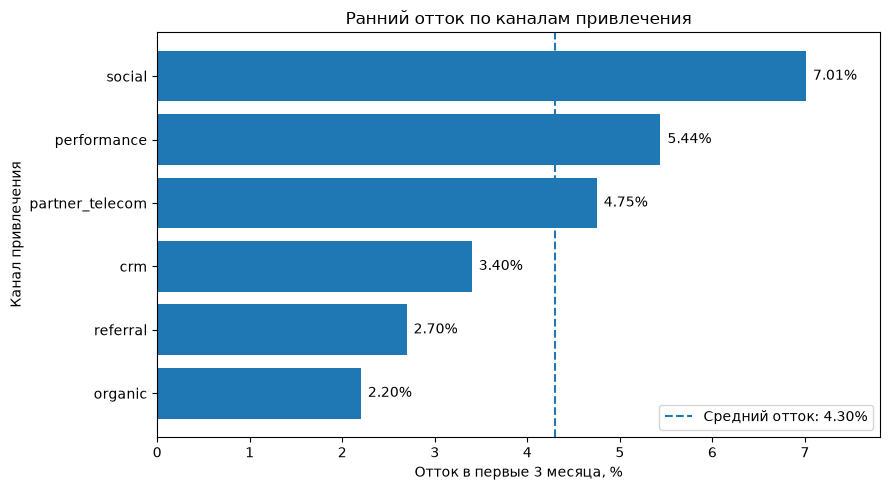

In [49]:
plot_df = (
    early_channel
    .reset_index()
    .sort_values("churn", ascending=False)
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    plot_df["acquisition_channel"]
    , plot_df["churn"]
)

ax.invert_yaxis()

ax.bar_label(
    bars
    , labels=[f"{x:.2f}%" for x in plot_df["churn"]]
    , padding=5
)

avg_churn = (
    (plot_df["churn"] * plot_df["observations"]).sum()
    / plot_df["observations"].sum()
)

ax.axvline(
    avg_churn
    , linestyle="--"
    , label=f"Средний отток: {avg_churn:.2f}%"
)

ax.set_title("Ранний отток по каналам привлечения")
ax.set_xlabel("Отток в первые 3 месяца, %")
ax.set_ylabel("Канал привлечения")
ax.set_xlim(0, plot_df["churn"].max() + 0.8)

ax.legend()

plt.tight_layout()
plt.show()


## Вывод по гипотезе 4

Отток в первые 3 месяца существенно различается между каналами привлечения. Канал social показывает максимальный отток - 7,01%, что более чем в три раза выше organic (2,20%) и на 2,71 п.п. выше среднего по рассматриваемым каналам (4,30%). Выше среднего также находятся performance и partner_telecom

In [50]:
channel_cohort = q("""
with params as 
(
    select '2026-08-30 00:00:00+00'::timestamptz as observation_end
)
, eligible_subs as 
(
    select
        s.subscription_id
        , s.owner_client_id
        , s.started_at
        , s.ended_at
        , c.acquisition_channel
    from prime.subscriptions s
    join prime.clients c
        on s.owner_client_id = c.client_id
    cross join params p
    where 1=1
    and s.started_at + interval '90 day' <= p.observation_end
)
, subscription_periods as 
(
    select
        s.subscription_id
        , s.acquisition_channel
        , date_trunc('quarter', s.started_at)::date as start_quarter
        , g.period_n + 1 as life_month
        , s.started_at + g.period_n * interval '30 day' as period_start
        , s.started_at + (g.period_n + 1) * interval '30 day' as period_end
        , s.ended_at
    from eligible_subs s
    cross join lateral generate_series(0, 2) as g(period_n)
    where 1=1
    and (
        s.ended_at is null
        or s.ended_at > s.started_at + g.period_n * interval '30 day'
    )
)
select
    start_quarter
    , acquisition_channel
    , count(*) as observations
    , avg(
        case
            when ended_at > period_start
            and ended_at <= period_end
            then 1.0
            else 0.0
        end
      ) * 100 as churn
from subscription_periods
where 1=1
group by start_quarter, acquisition_channel
order by start_quarter, acquisition_channel
""")

In [51]:
cohort_pivot = channel_cohort.pivot(
    index="start_quarter"
    , columns="acquisition_channel"
    , values="churn"
)

cohort_pivot

acquisition_channel,NaN,crm,organic,partner_telecom,performance,referral,social
start_quarter,,,,,,,
2024-01-01,4.000000,3.484688,2.142493,4.091374,5.643688,2.302459,6.759031
2024-04-01,3.972088,3.488372,2.253888,4.183151,5.293653,2.370188,7.073883
2024-07-01,3.818484,3.720847,2.270742,3.999759,5.624533,2.772021,7.153154
2024-10-01,3.525323,3.363347,2.150038,4.126965,5.372769,2.655100,6.941967
2025-01-01,3.867713,3.362626,2.202624,4.218317,5.456289,2.913136,7.052167
2025-04-01,2.952228,3.603360,2.142920,3.955143,5.574727,2.852372,7.038751
2025-07-01,3.867129,3.171939,2.430479,3.932913,5.338626,2.852486,6.751735
2025-10-01,4.158004,3.336536,2.281678,4.008144,5.459981,2.607200,7.115542
2026-01-01,3.947368,3.256553,1.966892,4.270442,5.341945,2.635804,7.047405


In [52]:
channel_cohort_full = channel_cohort[
    channel_cohort["start_quarter"] < pd.Timestamp("2026-04-01").date()
].copy()

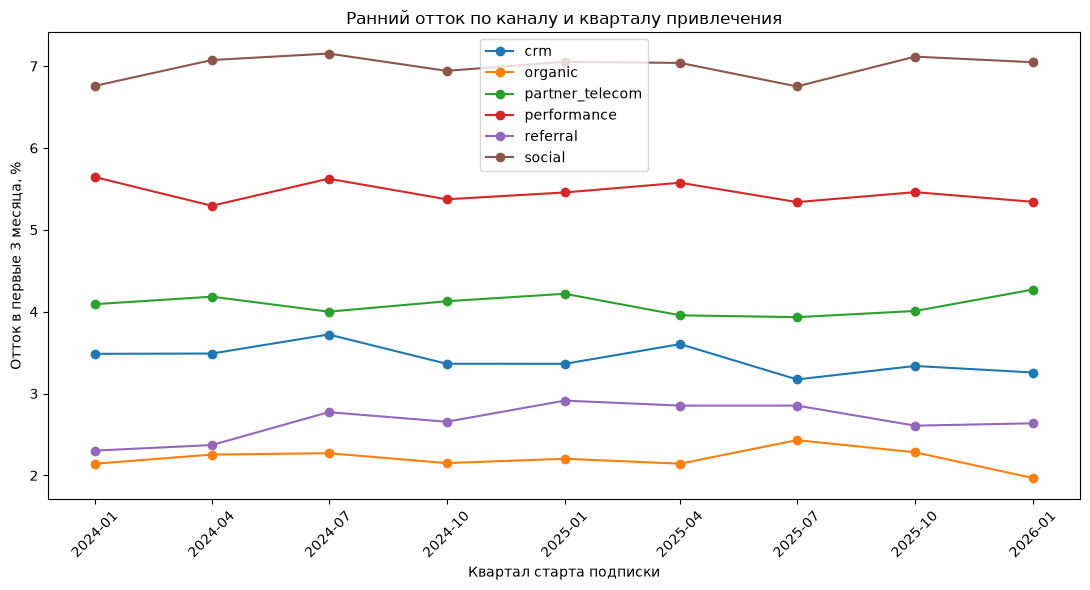

In [53]:
plt.figure(figsize=(11, 6))

for channel, data in channel_cohort_full.groupby("acquisition_channel"):
    if pd.isna(channel):
        continue

    plt.plot(
        data["start_quarter"]
        , data["churn"]
        , marker="o"
        , label=channel
    )

plt.title("Ранний отток по каналу и кварталу привлечения")
plt.xlabel("Квартал старта подписки")
plt.ylabel("Отток в первые 3 месяца, %")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Различия в оттоке между каналами примерно совпадают на всем рассматриваемом периоде. Во всех полных квартальных когортах максимальный отток наблюдается у social, затем у performance и partner_telecom. Минимальный у organic и referral. Следовательно, различия нельзя объяснить отдельным неудачным периодом привлечения.


## Экономика

In [54]:
spend = q("""
    select
        channel
        , spend_date
        , amount
    from prime.marketing_spend
    where 1=1
""")

spend.head()

,channel,spend_date,amount
0,crm,2025-01-06,12106.55
1,organic,2025-01-06,17554.05
2,partner_telecom,2025-01-06,60005.04
3,performance,2025-01-06,221394.89
4,referral,2025-01-06,19274.17


In [55]:
cac_channel = q("""
with spend as 
(
    select
        channel
        , sum(amount) as spend
    from prime.marketing_spend
    where 1=1
    and spend_date >= '2025-02-01'
    and spend_date < '2026-04-01'
    group by channel
)
, registrations as 
(
    select
        acquisition_channel as channel
        , count(distinct client_id) as registrations
    from prime.clients
    where 1=1
    and registered_at >= '2025-02-01'
    and registered_at < '2026-04-01'
    and acquisition_channel is not null
    group by acquisition_channel
)
select
    s.channel
    , s.spend
    , r.registrations
    , s.spend / r.registrations as cac
from spend s
join registrations r
    on s.channel = r.channel
where 1=1
order by cac
""")

cac_channel

,channel,spend,registrations,cac
0,organic,7121054.72,51652,137.866002
1,crm,5520652.65,25951,212.733715
2,referral,5902146.98,16947,348.270902
3,partner_telecom,26233949.82,38946,673.598054
4,social,27726762.39,34219,810.273894
5,performance,72518986.01,47191,1536.712212


In [56]:
early_channel_period = q("""
with params as 
(
    select '2026-08-30 00:00:00+00'::timestamptz as observation_end
)
, eligible_subs as 
(
    select
        s.subscription_id
        , s.started_at
        , s.ended_at
        , c.acquisition_channel
    from prime.subscriptions s
    join prime.clients c
        on s.owner_client_id = c.client_id
    cross join params p
    where 1=1
    and s.started_at >= '2025-02-01'
    and s.started_at < '2026-04-01'
    and s.started_at + interval '90 day' <= p.observation_end
    and c.acquisition_channel is not null
)
, periods as 
(
    select
        s.subscription_id
        , s.acquisition_channel
        , g.period_n + 1 as life_month
        , s.started_at + g.period_n * interval '30 day' as period_start
        , s.started_at + (g.period_n + 1) * interval '30 day' as period_end
        , s.ended_at
    from eligible_subs s
    cross join lateral generate_series(0, 2) as g(period_n)
    where 1=1
    and (
        s.ended_at is null
        or s.ended_at > s.started_at + g.period_n * interval '30 day'
    )
)
select
    acquisition_channel
    , count(*) as observations
    , avg(
        case
            when ended_at > period_start
            and ended_at <= period_end
            then 1.0
            else 0.0
        end
      ) * 100 as churn
from periods
where 1=1
group by acquisition_channel
order by churn desc
""")

early_channel_period

,acquisition_channel,observations,churn
0,social,67149,7.023187
1,performance,94181,5.460762
2,partner_telecom,78889,4.063938
3,crm,52365,3.366753
4,referral,34613,2.733077
5,organic,106373,2.196046


In [57]:
channel_economics = early_channel_period.merge(
    cac_channel[
        ["channel", "cac"]
    ]
    , left_on="acquisition_channel"
    , right_on="channel"
    , how="inner"
    , validate="1:1"
)

channel_economics = (
    channel_economics
    .drop(columns="channel")
    .sort_values("cac")
)

channel_economics

,acquisition_channel,observations,churn,cac
5,organic,106373,2.196046,137.866002
3,crm,52365,3.366753,212.733715
4,referral,34613,2.733077,348.270902
2,partner_telecom,78889,4.063938,673.598054
0,social,67149,7.023187,810.273894
1,performance,94181,5.460762,1536.712212


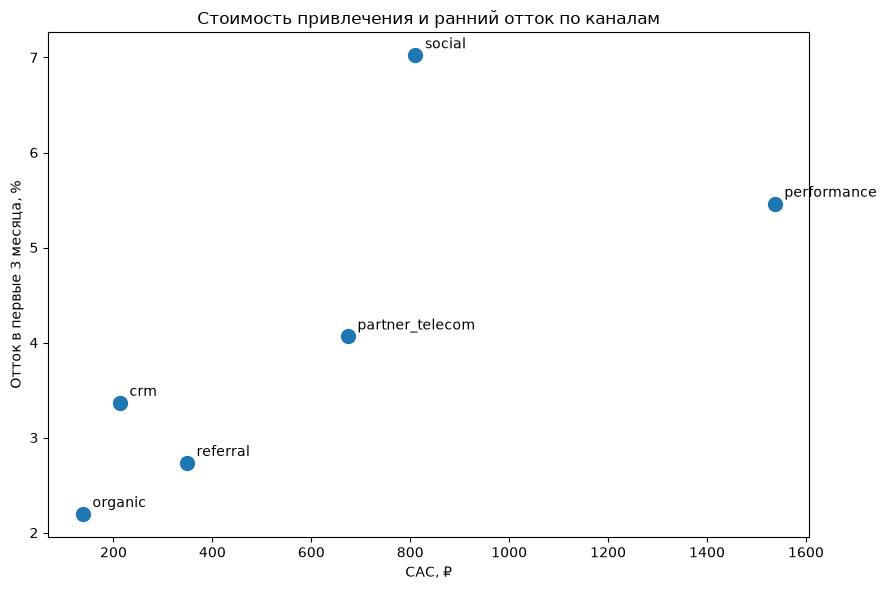

In [58]:
plt.figure(figsize=(9, 6))

plt.scatter(
    channel_economics["cac"]
    , channel_economics["churn"]
    , s=100
)

for _, row in channel_economics.iterrows():
    plt.annotate(
        row["acquisition_channel"]
        , (row["cac"], row["churn"])
        , xytext=(7, 5)
        , textcoords="offset points"
    )

plt.title("Стоимость привлечения и ранний отток по каналам")
plt.xlabel("CAC, ₽")
plt.ylabel("Отток в первые 3 месяца, %")

plt.tight_layout()
plt.show()

Наиболее эффективными являются organic и referral. У них низкая стоимость привлечения и низкий ранний отток. Performance имеет максимальный CAC (~1,5 тыс.) при оттоке около 5,5%, а social при CAC около 810 ₽ показывает максимальный отток (~7%). Таким образом, можно сказать, что высокая стоимость привлечения в ряде каналов не компенсируется более высоким качеством привлечённых клиентов.

In [59]:
conversion_channel = q("""
with registered as 
(
    select
        client_id
        , acquisition_channel
        , registered_at
    from prime.clients
    where 1=1
    and registered_at >= '2025-02-01'
    and registered_at < '2026-04-01'
    and acquisition_channel is not null
)
, first_sub as 
(
    select
        owner_client_id as client_id
        , min(started_at) as first_sub_at
    from prime.subscriptions
    where 1=1
    group by owner_client_id
)
select
    r.acquisition_channel
    , count(*) as registrations
    , count(*) filter (
        where f.first_sub_at >= r.registered_at
        and f.first_sub_at < r.registered_at + interval '30 day'
      ) as subscribers_30
    , count(*) filter (
        where f.first_sub_at >= r.registered_at
        and f.first_sub_at < r.registered_at + interval '30 day'
      )::float / count(*) as conversion_30
from registered r
left join first_sub f
    on r.client_id = f.client_id
where 1=1
group by r.acquisition_channel
order by conversion_30 desc
""")

conversion_channel

,acquisition_channel,registrations,subscribers_30,conversion_30
0,performance,47191,16263,0.344621
1,social,34219,11729,0.342763
2,partner_telecom,38946,13342,0.342577
3,referral,16947,5751,0.339352
4,organic,51652,17518,0.339154
5,crm,25951,8786,0.338561


In [60]:
subscriber_cac = cac_channel.merge(
    conversion_channel[
        ["acquisition_channel", "subscribers_30"]
    ],
    left_on="channel",
    right_on="acquisition_channel",
    how="inner",
    validate="1:1"
)

subscriber_cac["subscriber_cac"] = (
    subscriber_cac["spend"]
    / subscriber_cac["subscribers_30"]
)

subscriber_cac[
    ["channel", "subscriber_cac"]
].sort_values("subscriber_cac")

,channel,subscriber_cac
0,organic,406.499299
1,crm,628.346534
2,referral,1026.281861
3,partner_telecom,1966.268162
4,social,2363.949390
5,performance,4459.139520


In [61]:
subscriber_economics = (
    early_channel_period
    .merge(
        subscriber_cac[
            ["channel", "subscriber_cac"]
        ],
        left_on="acquisition_channel",
        right_on="channel",
        how="inner",
        validate="1:1"
    )
    .drop(columns="channel")
)

subscriber_economics

,acquisition_channel,observations,churn,subscriber_cac
0,social,67149,7.023187,2363.949390
1,performance,94181,5.460762,4459.139520
2,partner_telecom,78889,4.063938,1966.268162
3,crm,52365,3.366753,628.346534
4,referral,34613,2.733077,1026.281861
5,organic,106373,2.196046,406.499299


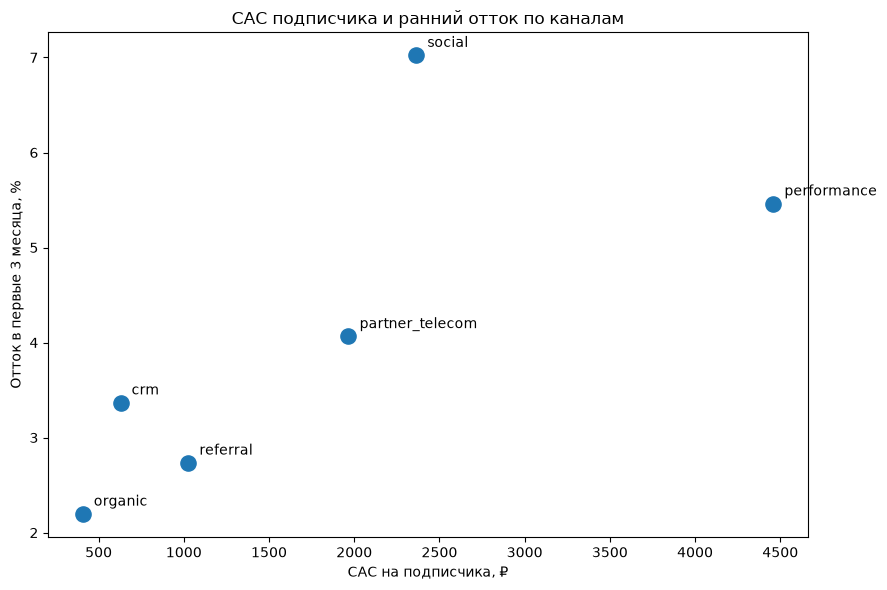

In [62]:
plt.figure(figsize=(9, 6))

plt.scatter(
    subscriber_economics["subscriber_cac"]
    , subscriber_economics["churn"]
    , s=120
)

for _, row in subscriber_economics.iterrows():
    plt.annotate(
        row["acquisition_channel"]
        , (row["subscriber_cac"], row["churn"])
        , xytext=(8, 6)
        , textcoords="offset points"
    )

plt.title("CAC подписчика и ранний отток по каналам")
plt.xlabel("CAC на подписчика, ₽")
plt.ylabel("Отток в первые 3 месяца, %")

plt.tight_layout()
plt.show()

In [63]:
subscriber_economics[
    [
        "acquisition_channel",
        "subscriber_cac",
        "churn"
    ]
].sort_values("subscriber_cac")

,acquisition_channel,subscriber_cac,churn
5,organic,406.499299,2.196046
3,crm,628.346534,3.366753
4,referral,1026.281861,2.733077
2,partner_telecom,1966.268162,4.063938
0,social,2363.949390,7.023187
1,performance,4459.139520,5.460762


Каналы существенно различаются по стоимости привлечения подписчика и по качеству привлечённой аудитории. Organic имеет минимальный CAC на подписчика и минимальный ранний отток. Performance имеет максимальный CAC при существенно более высоком оттоке, а social показывает самый высокий ранний отток при также высокой стоимости привлечения. Конверсия из регистрации в подписку между каналами почти одинакова, поэтому различия формируются в качестве и удержании подписчиков.

# факторная декомпозиция

In [64]:
decomp = channel_cohort_full.copy()

decomp["year"] = pd.to_datetime(
    decomp["start_quarter"]
).dt.year

decomp = (
    decomp[
        decomp["year"].isin([2024, 2025])
    ]
    .groupby(
        ["year", "acquisition_channel"],
        as_index=False
    )
    .apply(
        lambda x: pd.Series({
            "observations": x["observations"].sum(),
            "churn": (
                (x["churn"] * x["observations"]).sum()
                / x["observations"].sum()
            )
        }),
        include_groups=False
    )
)

decomp

,year,acquisition_channel,observations,churn
0,2024,crm,38650.0,3.518758
1,2024,organic,79810.0,2.211502
2,2024,partner_telecom,57296.0,4.099763
3,2024,performance,69896.0,5.463832
4,2024,referral,26449.0,2.559643
5,2024,social,50227.0,7.010174
6,2025,crm,44992.0,3.367265
7,2025,organic,91564.0,2.263990
8,2025,partner_telecom,67506.0,4.027790
9,2025,performance,80945.0,5.458027


In [65]:
decomp["share"] = (
    decomp["observations"]
    / decomp.groupby("year")["observations"].transform("sum")
)

decomp

,year,acquisition_channel,observations,churn,share
0,2024,crm,38650.0,3.518758,0.119909
1,2024,organic,79810.0,2.211502,0.247605
2,2024,partner_telecom,57296.0,4.099763,0.177757
3,2024,performance,69896.0,5.463832,0.216847
4,2024,referral,26449.0,2.559643,0.082056
5,2024,social,50227.0,7.010174,0.155826
6,2025,crm,44992.0,3.367265,0.120771
7,2025,organic,91564.0,2.263990,0.245783
8,2025,partner_telecom,67506.0,4.027790,0.181205
9,2025,performance,80945.0,5.458027,0.217279


In [66]:
overall = (
    decomp
    .groupby("year")
    .apply(
        lambda x: (
            x["share"] * x["churn"]
        ).sum(),
        include_groups=False
    )
)

overall

year
2024    4.185488
2025    4.188275
dtype: float64

In [67]:
print(
    "Изменение общего churn:",
    round(overall.loc[2025] - overall.loc[2024], 3),
    "п.п."
)

Изменение общего churn: 0.003 п.п.


In [68]:
quarter_overall = (
    channel_cohort_full
    .groupby("start_quarter")
    .apply(
        lambda x: pd.Series({
            "observations": x["observations"].sum()
            , "churn": (
                (x["churn"] * x["observations"]).sum()
                / x["observations"].sum()
            )
        }),
        include_groups=False
    )
    .reset_index()
)

quarter_overall

,start_quarter,observations,churn
0,2024-01-01,49164.0,4.161582
1,2024-04-01,88805.0,4.154045
2,2024-07-01,94884.0,4.273639
3,2024-10-01,96134.0,4.113009
4,2025-01-01,94201.0,4.214393
5,2025-04-01,94627.0,4.196477
6,2025-07-01,94774.0,4.122439
7,2025-10-01,96526.0,4.182293
8,2026-01-01,94393.0,4.109415


In [69]:
quarter_overall["change_pp"] = (
    quarter_overall["churn"].diff()
)

quarter_overall

,start_quarter,observations,churn,change_pp
0,2024-01-01,49164.0,4.161582,NaN
1,2024-04-01,88805.0,4.154045,-0.007536
2,2024-07-01,94884.0,4.273639,0.119594
3,2024-10-01,96134.0,4.113009,-0.160630
4,2025-01-01,94201.0,4.214393,0.101384
5,2025-04-01,94627.0,4.196477,-0.017916
6,2025-07-01,94774.0,4.122439,-0.074038
7,2025-10-01,96526.0,4.182293,0.059854
8,2026-01-01,94393.0,4.109415,-0.072878


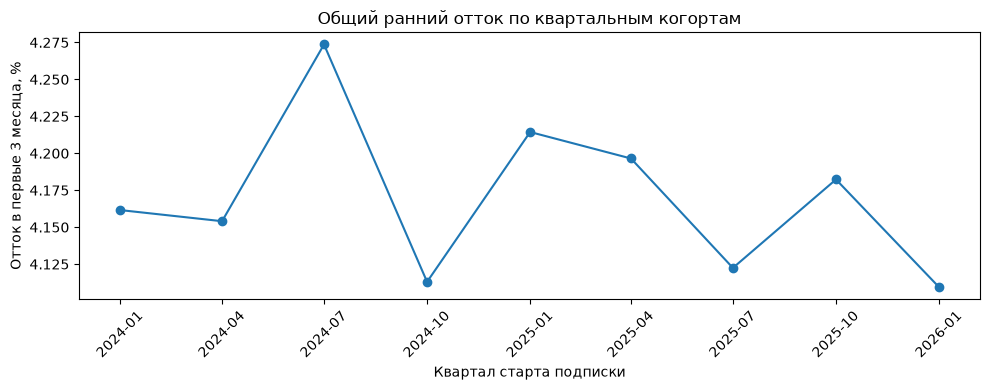

In [70]:
plt.figure(figsize=(10, 4))

plt.plot(
    quarter_overall["start_quarter"]
    , quarter_overall["churn"]
    , marker="o"
)

plt.title("Общий ранний отток по квартальным когортам")
plt.xlabel("Квартал старта подписки")
plt.ylabel("Отток в первые 3 месяца, %")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [71]:
quarter_overall["change_pp"] = quarter_overall["churn"].diff()

quarter_overall[
    ["start_quarter", "churn", "change_pp"]
]

,start_quarter,churn,change_pp
0,2024-01-01,4.161582,NaN
1,2024-04-01,4.154045,-0.007536
2,2024-07-01,4.273639,0.119594
3,2024-10-01,4.113009,-0.160630
4,2025-01-01,4.214393,0.101384
5,2025-04-01,4.196477,-0.017916
6,2025-07-01,4.122439,-0.074038
7,2025-10-01,4.182293,0.059854
8,2026-01-01,4.109415,-0.072878


In [72]:
biggest_change = (
    quarter_overall
    .dropna()
    .loc[
        quarter_overall["change_pp"].abs().idxmax()
    ]
)

biggest_change

start_quarter    2024-10-01
observations        96134.0
churn              4.113009
change_pp          -0.16063
Name: 3, dtype: object

In [73]:
period_before = pd.Timestamp("2024-07-01").date()
period_after = pd.Timestamp("2024-10-01").date()

before = channel_cohort_full[
    channel_cohort_full["start_quarter"] == period_before
].copy()

after = channel_cohort_full[
    channel_cohort_full["start_quarter"] == period_after
].copy()

In [74]:
before["share"] = (
    before["observations"]
    / before["observations"].sum()
)

after["share"] = (
    after["observations"]
    / after["observations"].sum()
)

In [75]:
decomp = before[
    ["acquisition_channel", "share", "churn"]
].merge(
    after[
        ["acquisition_channel", "share", "churn"]
    ],
    on="acquisition_channel",
    how="inner",
    suffixes=("_before", "_after"),
    validate="1:1"
)

decomp

,acquisition_channel,share_before,churn_before,share_after,churn_after
0,crm,0.118397,3.720847,0.117836,3.363347
1,organic,0.241347,2.270742,0.246260,2.150038
2,partner_telecom,0.174961,3.999759,0.171396,4.126965
3,performance,0.211363,5.624533,0.212776,5.372769
4,referral,0.081363,2.772021,0.079140,2.655100
5,social,0.153524,7.153154,0.151642,6.941967
6,NaN,0.019044,3.818484,0.020950,3.525323


In [76]:
decomp["mix_effect"] = (
    (decomp["share_after"] - decomp["share_before"])
    * decomp["churn_before"]
)

decomp["churn_effect"] = (
    decomp["share_before"]
    * (decomp["churn_after"] - decomp["churn_before"])
)

decomp["interaction"] = (
    (decomp["share_after"] - decomp["share_before"])
    * (decomp["churn_after"] - decomp["churn_before"])
)

decomp["total_effect"] = (
    decomp["mix_effect"]
    + decomp["churn_effect"]
    + decomp["interaction"]
)

In [77]:
effects = decomp[
    [
        "mix_effect",
        "churn_effect",
        "interaction",
        "total_effect"
    ]
].sum()

effects

mix_effect     -0.009593
churn_effect   -0.149934
interaction    -0.001103
total_effect   -0.160630
dtype: float64

In [78]:
before_total = (
    decomp["share_before"]
    * decomp["churn_before"]
).sum()

after_total = (
    decomp["share_after"]
    * decomp["churn_after"]
).sum()

print(
    "Факт:",
    round(after_total - before_total, 6),
    "п.п."
)

print(
    "Декомпозиция:",
    round(effects["total_effect"], 6),
    "п.п."
)

Факт: -0.16063 п.п.
Декомпозиция: -0.16063 п.п.


In [79]:
decomp[
    [
        "acquisition_channel",
        "mix_effect",
        "churn_effect",
        "interaction",
        "total_effect"
    ]
].sort_values("total_effect")

,acquisition_channel,mix_effect,churn_effect,interaction,total_effect
3,performance,0.007945,-0.053213,-0.000356,-0.045624
5,social,-0.013461,-0.032422,0.000397,-0.045486
0,crm,-0.002090,-0.042327,0.000201,-0.044216
1,organic,0.011156,-0.029132,-0.000593,-0.018568
4,referral,-0.006162,-0.009513,0.000260,-0.015415
6,NaN,0.007277,-0.005583,-0.000559,0.001135
2,partner_telecom,-0.014258,0.022256,-0.000453,0.007544


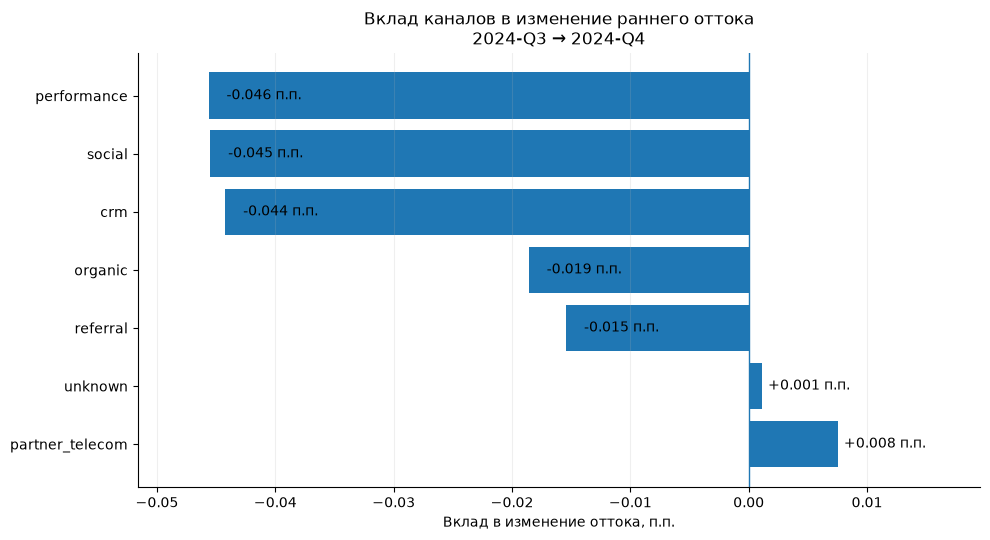

In [80]:
plot_decomp = decomp.copy()

plot_decomp["acquisition_channel"] = (
    plot_decomp["acquisition_channel"]
    .fillna("unknown")
)

plot_decomp = (
    plot_decomp
    .sort_values("total_effect", ascending=False)
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.barh(
    plot_decomp["acquisition_channel"]
    , plot_decomp["total_effect"]
)

ax.axvline(0, linewidth=1)

for bar, value in zip(
    bars,
    plot_decomp["total_effect"]
):
    y = bar.get_y() + bar.get_height() / 2

    if value < -0.01:
        # крупные отрицательные — подпись внутри столбца
        ax.text(
            value + 0.0015
            , y
            , f"{value:.3f} п.п."
            , va="center"
            , ha="left"
        )
    elif value < 0:
        # маленькие отрицательные — рядом со столбцом
        ax.text(
            value - 0.001
            , y
            , f"{value:.3f} п.п."
            , va="center"
            , ha="right"
        )
    else:
        ax.text(
            value + 0.0005
            , y
            , f"+{value:.3f} п.п."
            , va="center"
            , ha="left"
        )

ax.set_title(
    "Вклад каналов в изменение раннего оттока\n"
    "2024-Q3 → 2024-Q4"
)

ax.set_xlabel("Вклад в изменение оттока, п.п.")
ax.set_ylabel("")

ax.grid(
    axis="x",
    alpha=0.2
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xlim(
    plot_decomp["total_effect"].min() - 0.006,
    plot_decomp["total_effect"].max() + 0.012
)

plt.tight_layout()
plt.show()

Между 2024-Q3 и 2024-Q4 ранний отток снизился на 0,161 п.п. Наибольший вклад в снижение дали performance, social и crm. Partner_telecom, напротив, частично компенсировал улучшение. Основная часть снижения связана с уменьшением оттока внутри каналов